# MNIST above 99% with a CNN and Optuna

SYDE 577. Every model choice below is made on a validation set carved out of the 60k training images. The test set isn't loaded until the final section.

In [3]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import MNIST

SEED = 577 # for syde 577!! 
DEVICE = "cpu"
if torch.backends.mps.is_available(): DEVICE = "mps"
torch.device(DEVICE)
DATA_DIR = "data"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)


/Users/celine/Documents/school/tron/syde577/mnist_cnn/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data: train, validation and test splits

The 60k training images are split into about 50k train and 10k validation, stratified by digit with a fixed seed. Normalization statistics come from the train split only, so nothing about the held-out images reaches the model.

In [4]:
mnist_train = MNIST(DATA_DIR, train=True, download=True)
all_images = mnist_train.data.float().unsqueeze(1) / 255.0 # (60000, 1, 28, 28)
all_labels = mnist_train.targets # (60000, )

# get 1/6 of the images from each digit (0 to 9) for validation
random_generator = np.random.default_rng(SEED)
validation_indices = []
for digit in range(10):
    # find images related to a digit and randomize order
    indices = np.where(all_labels.numpy() == digit)[0]
    rng.shuffle(indices)

    # select 1/6 of them for validation and add to the total validation index list
    num_validation_images = round(len(indices) /6)
    val_indicies_for_digit = indices[:num_validation_images]
    for index in val_indicies_for_digit:
        validation_indices.append(index)

# Now that we have validation indicies, everything else is training, find by masking
validation_indices = np.sort(np.array(validation_indices))
validation_set = set(validation_indices)
training_indices = np.array([i for i in range(len(all_images)) if i not in validation_set])

Process it all

In [5]:
mean = all_images[training_indices].mean().item()
std = all_images[training_indices].std().item()
background_value = (0.0 - mean) / std

X_train = ((all_images[training_indices] - mean) / std).to(DEVICE)
y_train = all_labels[training_indices].to(DEVICE)
X_val = ((all_images[validation_indices] - mean) / std).to(DEVICE)
y_val = all_labels[validation_indices].to(DEVICE)

print(f"Train: {len(X_train)}, Val: {len(X_val)}")
print(f"Mean: {mean:.4f}, Std: {std:.4f}")
print("Validation images per digit:", torch.bincount(y_val.cpu(), minlength=10).tolist())

Train: 49999, Val: 10001
Mean: 0.1307, Std: 0.3081
Validation images per digit: [987, 1124, 993, 1022, 974, 904, 986, 1044, 975, 992]


## Shared model, augmentation and training code

MNIST has 60,000 28x28 images

In [ ]:
BASELINE = {
    # CNN construction 
    "n_blocks": 2,
    "base_filters": 32,
    "use_batchnorm": False,
    "head_method": "flatten",
    "dropout": 0.0,
    # CNN params
    "weight_decay": 0.0,
    "label_smoothing": 0.0,
    "rotation": 0.0,
    "translate": 0.0,
    "scale_jitter": 0.0,
    "lr": 1e-3,
    "schedule": "constant",
    "batch_size": 64,
}

# Basic CNN, True Hardcoded
class CNN_Basic(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        x = self.fc(x)
        return x

class CNN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        layers = []
        channels = 1 # starts at 1 because MNIST is in greyscale, then gets updated for the next layer
        spatial_size = 28
        # builds convolution layers
        for i in range(cfg["n_blocks"]):
            # num of filters doubles in each, ie 32, 64, 128, ...
            filters = cfg["base_filters"] * (2 ** i)
            # learnable filters
            layers.append(nn.Conv2d(channels, filters, 3, padding=1, bias=not cfg["use_batchnorm"]))
            if cfg["use_batchnorm"]:
                layers.append(nn.BatchNorm2d(filters))
            
            layers.append(nn.ReLU())
            layers.append(nn.Conv2d(filters, filters, 3, padding=1, bias=not cfg["use_batchnorm"]))
            if cfg["use_batchnorm"]:
                layers.append(nn.BatchNorm2d(filters))
            
            layers.append(nn.ReLU())
            # max of each 2x2 block to halve the spatial dimens
            layers.append(nn.MaxPool2d(2))
            spatial_size //= 2
            # get number of filters as feature maps
            channels = filters
            
        self.features = nn.Sequential(*layers)
        self.head_method = cfg["head_method"]
        if self.head_method == "gap":
            # global average pooling, average each feature map
            self.pool = nn.AdaptiveAvgPool2d((1, 1))
            self.flatten = nn.Flatten()
            n_inputs = channels
            
        else: # flatten method
            # flatten the remaining spatial dimensions
            self.pool = nn.Identity()
            self.flatten = nn.Flatten()
            # Getting the remaining spatial size, given MNIST input is 28x28
            n_inputs = channels * (spatial_size * spatial_size)

        # Classifier head
        self.dropout = nn.Dropout(cfg["dropout"])
        self.fc = nn.Linear(n_inputs, 10)

    def forward(self, x):
        x = self.features(x)
        if self.head_method == "gap":
            x = x.mean(dim=(2, 3))
        else: # flatten method
            x = x.flatten(1)
        return self.fc(self.dropout(x))

def augment(images, cfg):
    # check that augmentation is enabled
    if cfg["rotation"] == 0 and cfg["translate"] == 0 and cfg["scale_jitter"] == 0:
        return images

    # generate random transformations
    n = len(images)
    angle = (torch.rand(n, device=DEVICE) * 2 - 1) * math.radians(cfg["rotation"])
    scale = 1 + (torch.rand(n, device=DEVICE) * 2 - 1) * cfg["scale_jitter"]
    dx = (torch.rand(n, device=DEVICE) * 2 - 1) * cfg["translate"] * 2
    dy = (torch.rand(n, device=DEVICE) * 2 - 1) * cfg["translate"] * 2
    c = torch.cos(angle) / scale
    s = torch.sin(angle) / scale

    # apply all transformations
    theta = torch.zeros(n, 2, 3, device=DEVICE)
    theta[:, 0, 0] = c
    theta[:, 0, 1] = -s
    theta[:, 1, 0] = s
    theta[:, 1, 1] = c
    theta[:, 0, 2] = dx
    theta[:, 1, 2] = dy
    grid = F.affine_grid(theta, images.shape, align_corners=False)
    # grid_sample fills the edges with 0, so shift the background to 0 first, then shift it back after
    return F.grid_sample(images - background_value, grid, align_corners=False) + background_value

@torch.no_grad()
def accuracy(model, images, labels):
    model.eval()
    correct = 0
    # per batch, aggregate the correct number of guesses
    for i in range(0, len(images), 2048):
        next_i = i + 2048
        image_window = images[i:next_i]
        label_window = labels[i:next_i]
        correct += (model(image_window).argmax(1) == label_window).sum().item()
    return correct / len(images)


def run_training(cfg, seed, epochs, trial=None, use_basic = False):
    torch.manual_seed(seed)
    rng = torch.Generator().manual_seed(seed)

    if use_basic:
        model = CNN_Basic().to(DEVICE)
    else:
        model = CNN(cfg).to(DEVICE)
    # set up model and optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    batch_size = cfg["batch_size"]

    scheduler = None
    # use onecycle if applied to change learning rate through training time
    if cfg["schedule"] == "onecycle":
        steps = math.ceil(len(X_train) / batch_size) * epochs
        scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg["lr"], total_steps=steps)

    val_acc = []
    for epoch in range(epochs):
        model.train()
        indices = torch.randperm(len(X_train), generator=rng).to(DEVICE)
        # train on each batch 
        for i in range(0, len(X_train), batch_size):
            batch = indices[i:i+batch_size] # select batch and predict loss
            x = augment(X_train[batch], cfg)
            loss = F.cross_entropy(model(x), y_train[batch], label_smoothing=cfg["label_smoothing"])
            
            # update the CNN weights through adamw
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()

        # for each epoch save the accuracy
        val_acc.append(accuracy(model, X_val, y_val))
        if trial is not None:
            trial.report(val_acc[-1], epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return model, val_acc

## Test out the Basic CNN

In [7]:
def try_basic_cnn():
    model, val_acc = run_training(BASELINE, seed=42, epochs=10, use_basic=True)

    print("validation accuracy on the basic CNN per epoch:")
    for i, acc in enumerate(val_acc):
        print(f"Epoch {i+1}: {acc:.4f}")

    print(f"max validation accuracy is: {max(val_acc):.4f}")

# try_basic_cnn()

## Validate CNN Class (Non Basic)

### Try Augmenting inputs from MNIST

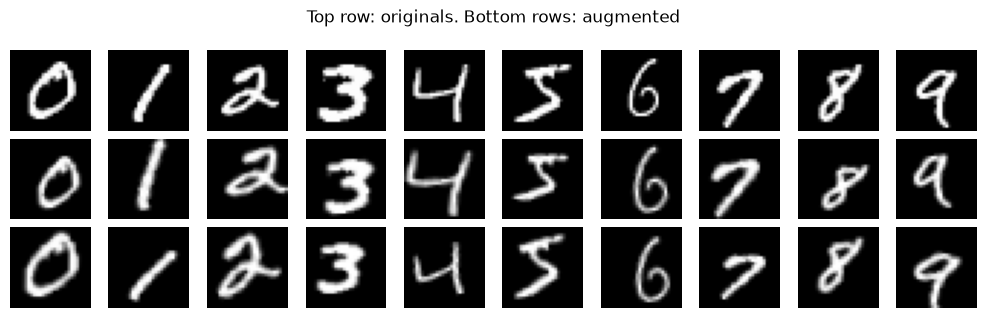

In [8]:

def try_augmentation():
    demo_cfg = BASELINE.copy()
    demo_cfg["rotation"] = 15
    demo_cfg["translate"] = 0.1
    demo_cfg["scale_jitter"] = 0.15

    torch.manual_seed(SEED)
    fig, axes = plt.subplots(3, 10, figsize=(10, 3.2))
    for col in range(10):
        digit_image = X_train[y_train == col][:1]
        axes[0, col].imshow(digit_image[0, 0].cpu(), cmap="gray")
        for row in (1, 2):
            axes[row, col].imshow(augment(digit_image, demo_cfg)[0, 0].cpu(), cmap="gray")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle("Top row: originals. Bottom rows: augmented")
    plt.tight_layout()
    plt.show()

try_augmentation()

## Our Network should be able to overfit if we train, then test on the same images

In [9]:
def try_overfit():
    small = CNN(BASELINE).to(DEVICE)
    opt = torch.optim.Adam(small.parameters(), lr=1e-3)
    xb, yb = X_train[:512], y_train[:512]
    for _ in range(100):
        loss = F.cross_entropy(small(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
    acc = accuracy(small, xb, yb)
    print(f"512-image overfit accuracy: {acc:.4f}")
    assert acc > 0.99

## With baseline settings, our CNN should be able to categorize. Accuracy doesn't matter here.

In [ ]:
def try_cnn():
    start = time.time()
    _, timing_val = run_training({**BASELINE, "n_blocks": 3, "use_batchnorm": True, "rotation": 10, "translate": 0.1}, SEED, 1)
    print(f"one augmented epoch: {time.time() - start:.1f}s, val acc {timing_val[-1]:.4f}")

# try_cnn()

one augmented epoch: 5.7s, val acc 0.9715


## Part 1: Manual exploration

Starting from a plain baseline (2 blocks, 32 filters, Adam at 1e-3, no regularization), each setting changes one factor and trains for 10 epochs with 2 seeds.

#### We expect some certain results that we can validate later:
**Augmentation**
We expect that orientation effects the semantic meaning of digits
- Translation shouldn't affect the accuracy that much, though if the network learns to expect digits in the middle of the image, then it could reduce accuracy
- Rotation may decrease accuracy a lot

In [17]:
MANUAL_EPOCHS = 10
MANUAL_SEEDS = [SEED, 556, 484]

# (group, setting name, what to change from the baseline)
SINGLE_EXPERIMENTS = [
    ("baseline", "baseline", {}),

    # architecture, increasing blocks, starting filter number, using batch norm, and head method
    ("depth", "3 blocks", {"n_blocks": 3}),
    ("depth", "4 blocks", {"n_blocks": 4}),
    ("width", "16 filters", {"base_filters": 16}),
    ("width", "64 filters", {"base_filters": 64}),
    ("batchnorm", "on", {"use_batchnorm": True}),
    ("head_method", "global avg pool", {"head_method": "gap", "n_blocks": 3}),
    ("head_method", "flatten (3 blocks)", {"n_blocks": 3}),

    # augmentation settings, just changing the R, T, S
    ("rotation", "±5°", {"rotation": 5}),
    ("rotation", "±10°", {"rotation": 10}),
    ("rotation", "±20°", {"rotation": 20}),
    ("rotation", "±90°", {"rotation": 90}),
    ("rotation", "±180°", {"rotation": 180}),

    ("translate", "5%", {"translate": 0.05}),
    ("translate", "10%", {"translate": 0.1}),
    ("translate", "20%", {"translate": 0.2}),
    ("scale", "10%", {"scale_jitter": 0.1}),

    # regularization
    ("dropout", "0.25", {"dropout": 0.25}),
    ("dropout", "0.5", {"dropout": 0.5}),
    ("dropout", "0.75", {"dropout": 0.75}),
    ("weight_decay", "0.0001", {"weight_decay": 1e-4}),
    ("weight_decay", "0.001", {"weight_decay": 1e-3}),
    ("weight_decay", "0.01", {"weight_decay": 1e-2}),
    ("label_smoothing", "0.1", {"label_smoothing": 0.1}),
    ("label_smoothing", "0.15", {"label_smoothing": 0.15}),
    ("label_smoothing", "0.2", {"label_smoothing": 0.2}),


    # optimizer
    ("learning_rate", "0.0001", {"lr": 1e-4}),
    ("learning_rate", "0.0005", {"lr": 5e-4}),
    ("learning_rate", "0.005", {"lr": 5e-3}),
    ("learning_rate", "0.01", {"lr": 1e-2}),
    ("schedule", "onecycle", {"schedule": "onecycle"}),
]

# caching outputs so that we don't need to rerun from scratch every time 
manual_path = RESULTS_DIR / "manual.csv"

def train_on_config(EXPERIMENTS):
    # cached value code is generated by Anthropic Claude
    if manual_path.exists():
        manual = pd.read_csv(manual_path)
        manual["val_acc"] = (
            manual["val_acc"]
            .astype(str)
            .str.strip("[]")
            .astype(float)
        )

        manual["final_val_acc"] = (
            manual["final_val_acc"]
            .astype(str)
            .str.strip("[]")
            .astype(float)
        )

        manual.to_csv(manual_path, index=False)
    else:
        manual = pd.DataFrame(columns=["group", "setting", "seed", "val_acc", "final_val_acc", "seconds"])

    for group, setting, change in EXPERIMENTS:
        for seed in MANUAL_SEEDS:
            already_done = ((manual["group"] == group) & (manual["setting"] == setting) & (manual["seed"] == seed)).any()
            
            # still print out if we already trained with this setting
            # printing cached value code is generated by Anthropic Claude
            if already_done:
                saved = manual[
                    (manual["group"] == group) &
                    (manual["setting"] == setting) &
                    (manual["seed"] == seed)
                ].iloc[0]

                print(
                    f"[CACHED] {group}, {setting}, seed={seed}, "
                    f"accuracy={saved['val_acc']:.4f}, "
                    f"time={saved['seconds']:.1f}s",
                    flush=True
                )
                continue

            # create version of baseline with the adjustment
            cfg = BASELINE.copy()
            for key, value in change.items():
                cfg[key] = value

            # get the 
            cfg.update(change)
            start = time.time()
            _, acc = run_training(cfg, seed, MANUAL_EPOCHS)
            score = acc[-1]
            seconds = time.time() - start

            manual.loc[len(manual)] = [group, setting, seed, score, acc[-1], seconds]
            manual.to_csv(manual_path, index=False)
            print(group, setting, seed, round(score, 4), str(round(seconds)) + "s")


train_on_config(SINGLE_EXPERIMENTS)

[CACHED] baseline, baseline, seed=577, accuracy=0.9904, time=32.6s
[CACHED] baseline, baseline, seed=556, accuracy=0.9883, time=32.7s
[CACHED] baseline, baseline, seed=484, accuracy=0.9897, time=31.1s
[CACHED] depth, 3 blocks, seed=577, accuracy=0.9912, time=40.1s
[CACHED] depth, 3 blocks, seed=556, accuracy=0.9904, time=43.6s
[CACHED] depth, 3 blocks, seed=484, accuracy=0.9902, time=44.3s
[CACHED] depth, 4 blocks, seed=577, accuracy=0.9914, time=52.6s
[CACHED] depth, 4 blocks, seed=556, accuracy=0.9913, time=54.0s
[CACHED] depth, 4 blocks, seed=484, accuracy=0.9903, time=52.4s
[CACHED] width, 16 filters, seed=577, accuracy=0.9877, time=14.2s
[CACHED] width, 16 filters, seed=556, accuracy=0.9877, time=14.9s
[CACHED] width, 16 filters, seed=484, accuracy=0.9886, time=13.4s
[CACHED] width, 64 filters, seed=577, accuracy=0.9900, time=81.4s
[CACHED] width, 64 filters, seed=556, accuracy=0.9853, time=82.0s
[CACHED] width, 64 filters, seed=484, accuracy=0.9858, time=82.7s
[CACHED] batchnorm,

So the consistently good options are 
batch norm
label smoothing
dropout 0.5

depth has potential

In [ ]:
# a few of the good ones together, since one at a time cant show how they interact
MULTI_EXPERIMENTS = [
    # Combine the strongest individual improvements
    ("combined", "bn + ls",
     {"use_batchnorm": True, "label_smoothing": 0.15}),

    ("combined", "dropout + ls",
     {"dropout": 0.5, "label_smoothing": 0.15}),

    ("combined", "bn + dropout",
     {"use_batchnorm": True, "dropout": 0.5}),

    ("combined", "bn + ls + dropout",
     {"use_batchnorm": True, "label_smoothing": 0.15,
      "dropout": 0.5}),

    # Test depth
    ("combined", "bn + ls + dropout + 3 blocks",
     {"use_batchnorm": True, "label_smoothing": 0.15,
      "dropout": 0.5, "n_blocks": 3}),

    # Test augmentation separately
    ("combined", "bn + ls + dropout + mild aug",
     {"use_batchnorm": True, "label_smoothing": 0.15,
      "dropout": 0.5, "rotation": 10,
      "translate": 0.05, "scale_jitter": 0.1}),

    # Test learning rate schedule
    ("combined", "bn + ls + dropout + onecycle",
     {"use_batchnorm": True, "label_smoothing": 0.15,
      "dropout": 0.5, "schedule": "onecycle"}),

    # Test larger batch
    ("combined", "bn + ls + dropout + batch 256",
     {"use_batchnorm": True, "label_smoothing": 0.15,
      "dropout": 0.5, "batch_size": 32}),

    ("combined", "... + onecycle 5e-3", 
     {"use_batchnorm": True, "label_smoothing": 0.15, "n_blocks": 3,
      "dropout": 0.5, "schedule": "onecycle", "lr": 5e-3}),

    ("combined", "... + mild aug", 
     {"use_batchnorm": True, "label_smoothing": 0.15, "n_blocks": 3,
      "dropout": 0.5, "schedule": "onecycle", "lr": 5e-3,
      "rotation": 10, "translate": 0.05, "scale_jitter": 0.1}),

    ("combined", "... + mild aug, batch 32", 
     {"use_batchnorm": True, "label_smoothing": 0.15, "n_blocks": 3,
      "dropout": 0.5, "schedule": "onecycle", "lr": 5e-3,
      "rotation": 10, "translate": 0.05, "scale_jitter": 0.1,
      "batch_size": 32}),
]

train_on_config(MULTI_EXPERIMENTS)

[CACHED] combined, bn + ls, seed=577, accuracy=0.9942, time=3677.0s
[CACHED] combined, bn + ls, seed=556, accuracy=0.9935, time=2741.1s
[CACHED] combined, bn + ls, seed=484, accuracy=0.9935, time=901.4s
[CACHED] combined, dropout + ls, seed=577, accuracy=0.9933, time=5511.8s
[CACHED] combined, dropout + ls, seed=556, accuracy=0.9942, time=29.3s
[CACHED] combined, dropout + ls, seed=484, accuracy=0.9934, time=28.5s
[CACHED] combined, bn + dropout, seed=577, accuracy=0.9918, time=37.6s
[CACHED] combined, bn + dropout, seed=556, accuracy=0.9914, time=34.3s
[CACHED] combined, bn + dropout, seed=484, accuracy=0.9909, time=33.9s
[CACHED] combined, bn + ls + dropout, seed=577, accuracy=0.9939, time=35.9s
combined bn + ls + dropout 556 0.9935 34s
combined bn + ls + dropout 484 0.9944 34s
combined bn + ls + dropout + 3 blocks 577 0.9949 47s
combined bn + ls + dropout + 3 blocks 556 0.9954 47s
combined bn + ls + dropout + 3 blocks 484 0.9946 44s
combined bn + ls + dropout + mild aug 577 0.9939 3

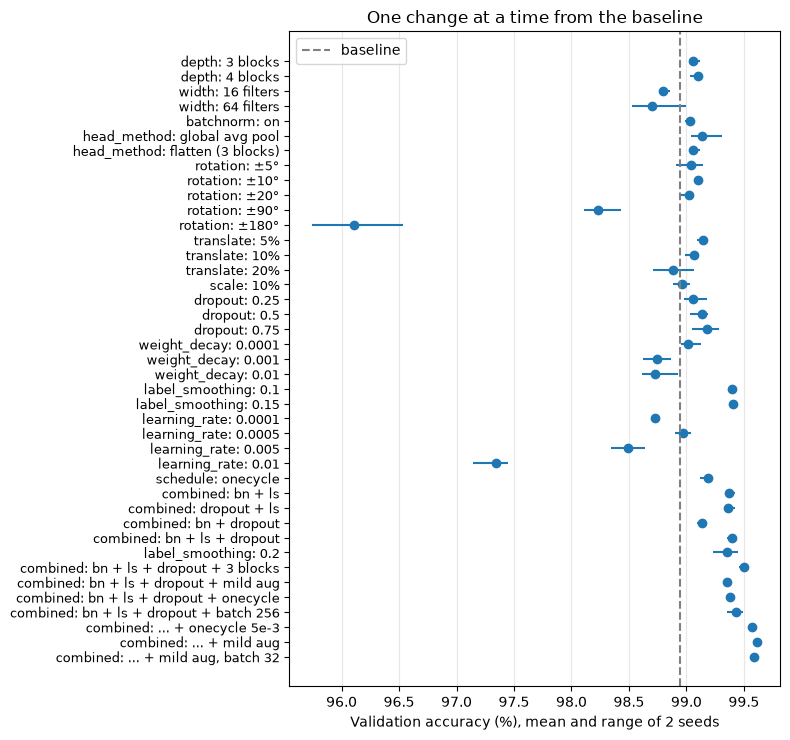

,group,setting,val_acc,low,high,seconds
0,baseline,baseline,0.9895,0.9883,0.9904,32.1154
1,depth,3 blocks,0.9906,0.9902,0.9912,42.6530
2,depth,4 blocks,0.9910,0.9903,0.9914,52.9910
3,width,16 filters,0.9880,0.9877,0.9886,14.1871
4,width,64 filters,0.9870,0.9853,0.9900,82.0329
5,batchnorm,on,0.9903,0.9899,0.9907,35.3874
6,head_method,global avg pool,0.9914,0.9904,0.9931,40.0679
7,head_method,flatten (3 blocks),0.9906,0.9902,0.9912,42.0711
8,rotation,±5°,0.9904,0.9891,0.9914,32.6537
9,rotation,±10°,0.9910,0.9908,0.9914,30.2976


In [31]:
manual = pd.read_csv(manual_path)

# Average accuracy from each seed
summary = manual.groupby(["group", "setting"], sort=False).agg(
    val_acc=("val_acc", "mean"), low=("val_acc", "min"), high=("val_acc", "max"), seconds=("seconds", "mean")
).reset_index()
baseline_acc = summary[summary["group"] == "baseline"]["val_acc"].item()

# Plotting code was generated by AnthropicClaude
plot_data = summary[summary["group"] != "baseline"].iloc[::-1].reset_index(drop=True)
labels = plot_data["group"] + ": " + plot_data["setting"]
positions = np.arange(len(plot_data))

plt.figure(figsize=(8, 7.5))
plt.hlines(positions, plot_data["low"] * 100, plot_data["high"] * 100)
plt.plot(plot_data["val_acc"] * 100, positions, "o")
plt.axvline(baseline_acc * 100, color="gray", linestyle="--", label="baseline")
plt.yticks(positions, labels, fontsize=9)
plt.xlabel("Validation accuracy (%), mean and range of 2 seeds")
plt.title("One change at a time from the baseline")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

summary.round(4)

## Part 2: Optuna search


[I 2026-11-10 10:02:16,896] A new study created in memory with name: no-name-44c8770c-8e8c-4363-a089-fe946f27afbf
[I 2026-11-10 10:02:57,256] Trial 0 finished with value: 0.9945005499450055 and parameters: {'use_batchnorm': False, 'schedule': 'onecycle', 'head_method': 'flatten', 'lr': 0.005162377525327628, 'weight_decay': 0.0005356612804031043, 'batch_size': 64, 'dropout': 0.2179257588961172, 'label_smoothing': 0.12987987589152264, 'rotation': 3.475786649919543, 'translate': 0.03124493238809245, 'scale_jitter': 0.08971516220303215}. Best is trial 0 with value: 0.9945005499450055.
[I 2026-11-10 10:03:41,290] Trial 1 finished with value: 0.9937006299370063 and parameters: {'use_batchnorm': True, 'schedule': 'constant', 'head_method': 'flatten', 'lr': 0.0021215372617303004, 'weight_decay': 6.108709370422906e-05, 'batch_size': 64, 'dropout': 0.5911557433506465, 'label_smoothing': 0.11617392739993372, 'rotation': 9.314012070302486, 'translate': 0.038569711159176824, 'scale_jitter': 0.06602

Best accuracy: 0.9965003499650035
Best parameters: {'use_batchnorm': True, 'schedule': 'onecycle', 'head_method': 'gap', 'lr': 0.0012911685461740633, 'weight_decay': 1.5000562368567667e-06, 'batch_size': 32, 'dropout': 0.3362187494871352, 'label_smoothing': 0.14444677210981224, 'rotation': 0.6990558688862705, 'translate': 0.08707921025007265, 'scale_jitter': 0.05454844880037764}


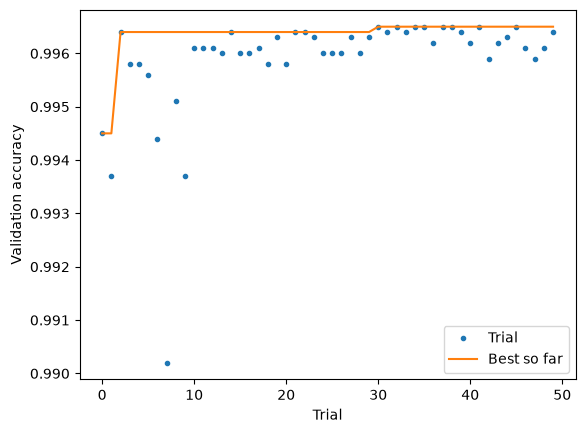

In [28]:
N_TRIALS = 50
SEARCH_EPOCHS = 15

def objective(trial):
    config = {
        "n_blocks": 3,
        "base_filters": 32,
        "use_batchnorm": trial.suggest_categorical("use_batchnorm", [True, False]),
        "schedule": trial.suggest_categorical("schedule", ["constant", "onecycle"]),
        "head_method": trial.suggest_categorical("head_method", ["gap", "flatten"]),
        
        "lr": trial.suggest_float("lr", 1e-3, 8e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64]),
        "dropout": trial.suggest_float("dropout", 0.2, 0.6),
        "label_smoothing": trial.suggest_float("label_smoothing", 0.05, 0.15),
        "rotation": trial.suggest_float("rotation", 0, 15),
        "translate": trial.suggest_float("translate", 0, 0.1),
        "scale_jitter": trial.suggest_float("scale_jitter", 0, 0.1),
    }

    _, val_acc = run_training(config, SEED, SEARCH_EPOCHS)
    return val_acc[-1]


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=N_TRIALS)

print("Best accuracy:", study.best_value)
print("Best parameters:", study.best_params)


# Plotting code is generated by Anthropic Claude
values = [t.value for t in study.trials]

plt.plot(values, ".", label="Trial")
plt.plot(np.maximum.accumulate(values), label="Best so far")
plt.xlabel("Trial")
plt.ylabel("Validation accuracy")
plt.legend()
plt.show()

## Part 3: Final model

The best trial's configuration is frozen here, before the test set is loaded. It trains for 30 epochs on the training split with 5 seeds. All 5 test results are reported, because picking the best seed by test accuracy would turn the test set into another selection step.

In [29]:
FINAL_EPOCHS = 30
FINAL_SEEDS = [577, 587, 123, 190, 999, 234]

FINAL_CFG = {
    **BASELINE,
    **study.best_params,
    "n_blocks": 3,
    "base_filters": 32,
    "use_batchnorm": True,
    "head_method": "flatten",
    "schedule": "onecycle",
}
print(json.dumps(FINAL_CFG, indent=2))

# The test set is loaded here and nowhere earlier
mnist_test = MNIST(DATA_DIR, train=False, download=True)
X_test = ((mnist_test.data.float().unsqueeze(1) / 255.0 - mean) / std).to(DEVICE)
y_test = mnist_test.targets.to(DEVICE)

final_path = RESULTS_DIR / "final.csv"
final = pd.read_csv(final_path) if final_path.exists() else pd.DataFrame(columns=["seed", "val_acc", "test_acc"])
for seed in FINAL_SEEDS:
    ckpt = RESULTS_DIR / f"final_seed{seed}.pt"
    if (final.seed == seed).any():
        continue
    model, val_curve = run_training(FINAL_CFG, seed, FINAL_EPOCHS)
    torch.save(model.state_dict(), ckpt)
    final.loc[len(final)] = [seed, val_curve[-1], accuracy(model, X_test, y_test)]
    final.to_csv(final_path, index=False)
    print(int(seed), f"val {val_curve[-1]:.4f}", flush=True)

print(final.round(4).to_string(index=False))
print(f"test accuracy: {final.test_acc.mean() * 100:.2f}% ± {final.test_acc.std() * 100:.2f}% over {len(final)} seeds")
print(f"validation accuracy: {final.val_acc.mean() * 100:.2f}% ± {final.val_acc.std() * 100:.2f}%")

{
  "n_blocks": 3,
  "base_filters": 32,
  "use_batchnorm": true,
  "head_method": "flatten",
  "dropout": 0.3362187494871352,
  "weight_decay": 1.5000562368567667e-06,
  "label_smoothing": 0.14444677210981224,
  "rotation": 0.6990558688862705,
  "translate": 0.08707921025007265,
  "scale_jitter": 0.05454844880037764,
  "lr": 0.0012911685461740633,
  "schedule": "onecycle",
  "batch_size": 32
}
 seed  val_acc  test_acc
577.0   0.9967    0.9973
587.0   0.9961    0.9969
123.0   0.9960    0.9975
190.0   0.9965    0.9971
999.0   0.9957    0.9968
234.0   0.9962    0.9969
test accuracy: 99.71% ± 0.03% over 6 seeds
validation accuracy: 99.62% ± 0.04%


27 test errors for the first seed


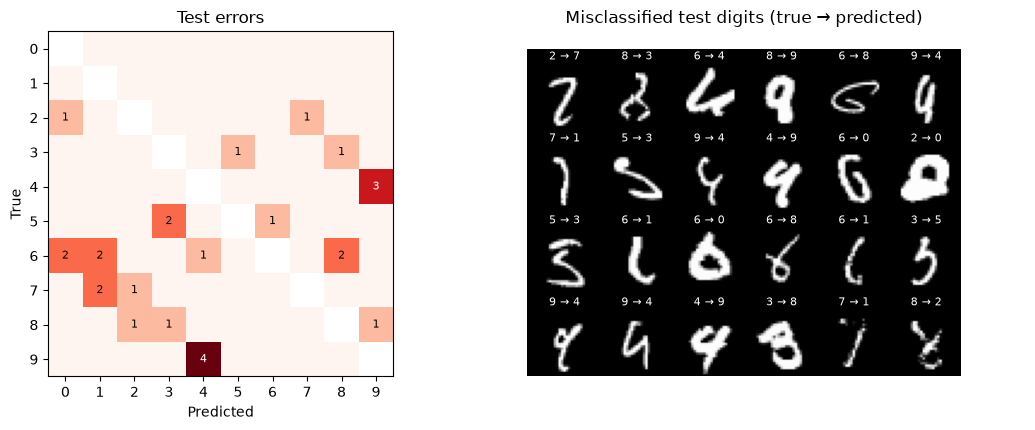

In [30]:
# Plotting code is generated by Anthropic Claude
model = CNN(FINAL_CFG).to(DEVICE)
model.load_state_dict(torch.load(RESULTS_DIR / f"final_seed{FINAL_SEEDS[0]}.pt", map_location=DEVICE))
model.eval()
with torch.no_grad():
    pred = torch.cat([model(X_test[i : i + 2048]).argmax(1) for i in range(0, len(X_test), 2048)])
wrong = (pred != y_test).nonzero().flatten().cpu()
print(len(wrong), "test errors for the first seed")

matrix = torch.zeros(10, 10, dtype=int)
for t, p in zip(y_test.cpu(), pred.cpu()):
    matrix[t, p] += 1
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
errors_only = matrix.clone().float()
errors_only.fill_diagonal_(float("nan"))
axes[0].imshow(errors_only, cmap="Reds")
for r in range(10):
    for c in range(10):
        if r != c and matrix[r, c]:
            axes[0].text(c, r, int(matrix[r, c]), ha="center", va="center", fontsize=8,
                         color="white" if matrix[r, c] >= 3 else "black")
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Test errors")
axes[1].axis("off")
axes[1].set_title("Misclassified test digits (true → predicted)")
inner = axes[1].inset_axes([0, 0, 1, 0.95])
inner.axis("off")
show = wrong[:24]
canvas = torch.zeros(4 * 34, 6 * 30)
for i, idx in enumerate(show):
    r, c = i // 6, i % 6
    canvas[r * 34 + 6 : r * 34 + 34, c * 30 + 1 : c * 30 + 29] = X_test[idx, 0].cpu() * std + mean
    inner.text(c * 30 + 15, r * 34 + 4, f"{y_test[idx].item()} → {pred[idx].item()}", ha="center", fontsize=8, color="white")
inner.imshow(canvas, cmap="gray")
plt.tight_layout()
plt.show()